# Cross-Domain Generalization Across 10 Product Categories

Evaluates domain transfer performance of the classifier across 10 Amazon product categories.

**Generates:** `13_cross_domain_category_performance.png`


### 1. Environment & Path Configuration

In [1]:
import os
import sys
import matplotlib.pyplot as plt
%matplotlib inline

# Navigate to project root if running from notebooks directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print('Active Project Root:', os.getcwd())


Active Project Root: e:\ML\mini project 2


### 2. Execution & Visualization Generation

Loading category transfer metrics from results/metrics\cross_dataset_category_performance.csv...


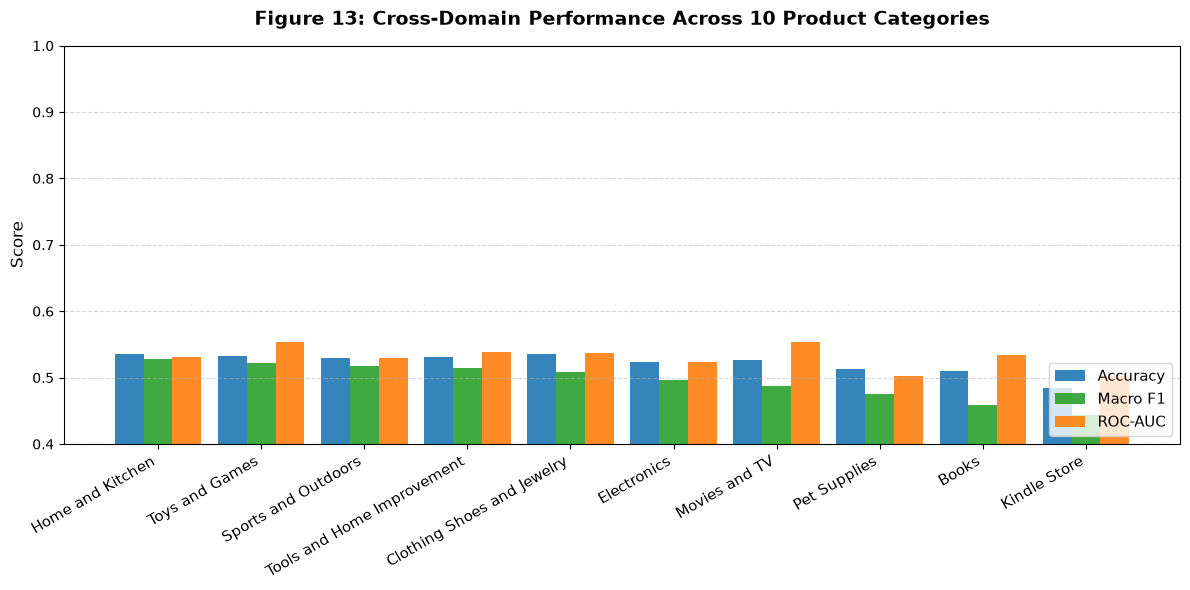

Successfully generated and saved: results/figures\13_cross_domain_category_performance.png


In [2]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR = "results/figures"
METRICS_DIR = "results/metrics"
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

# 1. Load or run cross-domain category performance
csv_path = os.path.join(METRICS_DIR, "cross_dataset_category_performance.csv")

if os.path.exists(csv_path):
    print(f"Loading category transfer metrics from {csv_path}...")
    df_cat = pd.read_csv(csv_path)
else:
    print("Running cross-dataset evaluation across 10 Amazon categories...")
    from src.data_loader import load_salminen_dataset
    from src.evaluate import evaluate_classifier
    
    model = joblib.load("models/best_model_enhanced.joblib")
    df_salminen = load_salminen_dataset()
    categories = sorted(df_salminen["product_category"].unique())
    records = []
    
    for cat in categories:
        sub = df_salminen[df_salminen["product_category"] == cat]
        res = evaluate_classifier(model, sub["review_text"], sub["label"], model_name=cat)
        records.append({
            "category": cat,
            "accuracy": res["accuracy"],
            "macro_f1": res["macro_f1"],
            "roc_auc": res["roc_auc"],
            "n_samples": len(sub)
        })
    df_cat = pd.DataFrame(records).sort_values(by="macro_f1", ascending=False)
    df_cat.to_csv(csv_path, index=False)

# 2. Generate Figure 13: Cross-Domain Category Performance
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(df_cat))
width = 0.28

rects1 = ax.bar(x - width, df_cat["accuracy"], width, label="Accuracy", color="#1f77b4", alpha=0.9)
rects2 = ax.bar(x, df_cat["macro_f1"], width, label="Macro F1", color="#2ca02c", alpha=0.9)
rects3 = ax.bar(x + width, df_cat["roc_auc"], width, label="ROC-AUC", color="#ff7f0e", alpha=0.9)

ax.set_ylabel("Score", fontsize=12)
ax.set_title("Figure 13: Cross-Domain Performance Across 10 Product Categories", fontsize=14, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(df_cat["category"], rotation=30, ha="right", fontsize=11)
ax.legend(loc="lower right", frameon=True, fontsize=11)
ax.set_ylim(0.4, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
out_fig = os.path.join(FIGURES_DIR, "13_cross_domain_category_performance.png")
out_met = os.path.join(METRICS_DIR, "13_cross_domain_category_performance.png")
fig.savefig(out_fig, dpi=300, bbox_inches="tight")
fig.savefig(out_met, dpi=300, bbox_inches="tight")
plt.show()

print(f"Successfully generated and saved: {out_fig}")
